
# **Topics — Black–Scholes and Delta Hedging**

**Main question:** How can we price and hedge an option without creating arbitrage opportunities?

Previously, we studied option pricing using the **Binomial Model** and **Monte Carlo Simulation**.

This topic extends the replication idea from discrete time to **continuous time** under the Black–Scholes model.

**Learning objectives:**

- Understand **no-arbitrage pricing** and self-financing replication.
- Apply the Black–Scholes formulas to price European calls and puts.
- Understand the Greeks, especially **Delta and Gamma**.
- Construct a continuous-time **Delta-Hedging Strategy**.
- Derive the **Black–Scholes PDE** using Itô's Lemma.
- Simulate discrete hedging and measure replication errors.


### **Black–Scholes: No-Arbitrage and Replication**

The central challenge in option pricing is to find a price that creates **no arbitrage opportunities**.

**European option payoffs:**

$$
g_{\text{call}}(S_T)=(S_T-K)^+=\max(S_T-K,0)
$$

$$
g_{\text{put}}(S_T)=(K-S_T)^+=\max(K-S_T,0)
$$

**Self-financing strategy:** After the initial investment, no money is added to or withdrawn from the portfolio. Rebalancing is financed by trading stock and using the bank account.

Let $\Pi_t$ denote the portfolio value at time $t$.

A strategy **replicates** an option if its terminal wealth matches the option payoff in every scenario:

$$
\boxed{\Pi_T=g(S_T)}
$$

The initial portfolio value $\Pi_0$ is the **replication cost**.

By the **no-arbitrage principle**:

$$
\boxed{\text{Option Price}=\text{Replication Cost}=\Pi_0}
$$

> **Intuition:** A trader sells an option and uses the premium to build a replicating portfolio. At maturity, the portfolio provides exactly the cash required to pay the option holder.

### Replication Strategy

<img src="replication.png" alt="Replication Strategy" width="750">



### Example: One-Period Binomial Replication

Suppose a European call has:

$$
S_0=100,\quad K=100,\quad r=0
$$

At maturity, the stock price is either $90$ or $110$, giving call payoffs of $0$ and $10$.

**Step 1 — Calculate the hedge ratio**

$$
\Delta=\frac{10-0}{110-90}=\boxed{0.5}
$$

The replicating portfolio holds **0.5 shares**.

**Step 2 — Construct the portfolio**

Buy 0.5 shares and borrow £45.

| At maturity | $S_T=90$ | $S_T=110$ |
|---|---:|---:|
| 0.5 shares | £45 | £55 |
| Loan repayment | −£45 | −£45 |
| **Portfolio value** | **£0** | **£10** |
| **Call payoff** | **£0** | **£10** |

The portfolio exactly matches the call payoff in both scenarios.

**Step 3 — Calculate the replication cost**

$$
\boxed{\Pi_0=0.5\times100-45=£5}
$$

By no-arbitrage:

$$
\boxed{C_0=\Pi_0=£5}
$$

> **Key insight:** Replication pricing does not require the probabilities of the stock-price outcomes.



### The Black–Scholes Model

The binomial model replicates option payoffs through trading at **discrete times**.

The Black–Scholes model extends replication to **continuous time**, where the stock follows a continuous stochastic process.

**Stock price — Geometric Brownian Motion (GBM):**

$$
\boxed{dS_t=\mu S_t\,dt+\sigma S_t\,dW_t,\qquad S_0>0}
$$

**Risk-free bank account:**

$$
dB_t=rB_t\,dt
\qquad\Rightarrow\qquad
B_t=B_0e^{rt}
$$

**Main assumptions:**

- The stock pays no dividends; $\mu$, $\sigma>0$ and $r$ are constant.
- Short-selling and borrowing are allowed.
- Asset quantities are divisible.
- No transaction costs or bid–ask spreads.
- Borrowing and lending use the same risk-free rate $r$.
- Continuous trading is allowed.
- Trading decisions use only information available up to the current time.
- Trading strategies must satisfy suitable admissibility conditions.

> **Key difference:** The binomial model uses discrete rebalancing, while Black–Scholes assumes continuous dynamic hedging.



### Black–Scholes Call-Price Formula

For a European call with strike $K$ and maturity $T$:

$$
g(S_T)=(S_T-K)^+
$$

**Notation:**

- $C(s,t)$: call price at time $t$, given $S_t=s$.
- $\tau=T-t$: time remaining until maturity.
- $N(x)$: standard normal cumulative distribution function (CDF).
- $\varphi(x)$: standard normal probability density function (PDF).

**Black–Scholes Formula:**

$$
\boxed{C(s,t)=sN(d_1)-Ke^{-r\tau}N(d_2)}
$$

where

$$
d_1=\frac{\ln(s/K)+(r+\frac12\sigma^2)\tau}{\sigma\sqrt{\tau}}
$$

$$
d_2=\frac{\ln(s/K)+(r-\frac12\sigma^2)\tau}{\sigma\sqrt{\tau}}
$$

Hence,

$$
\boxed{d_1=d_2+\sigma\sqrt{\tau}}
$$

> **Why does the formula use $r$ instead of $\mu$?**
>
> Delta hedging eliminates the stock-price risk and the dependence on the expected return $\mu$. By no-arbitrage, the resulting riskless portfolio must earn the risk-free rate $r$.
>
> Therefore, the Black–Scholes option price depends on $r$, not $\mu$.



### Understanding $d_1$ and $d_2$

**Step 1 — Decompose the call payoff**

Using the indicator function:

$$
(S_T-K)^+
=S_T\mathbf{1}_{\{S_T>K\}}
-K\mathbf{1}_{\{S_T>K\}}
$$

Under the **risk-neutral measure** $\mathbb Q$, the stock follows GBM with drift $r$:

$$
S_T=s\exp\left[
\left(r-\frac12\sigma^2\right)\tau
+\sigma\sqrt{\tau}Z
\right],
\qquad Z\sim N(0,1)
$$

### Derivation of $d_2$: Exercise Probability

The call expires in the money when $S_T>K$.

Taking logarithms:

$$
S_T>K
\iff
Z>-\frac{\ln(s/K)+(r-\frac12\sigma^2)\tau}
{\sigma\sqrt{\tau}}
=-d_2
$$

Therefore,

$$
\boxed{\mathbb Q(S_T>K\mid S_t=s)=N(d_2)}
$$

$N(d_2)$ is the **risk-neutral probability of expiring in the money**.

### Derivation of $d_1$: Stock-Value-Weighted Term

Consider the discounted stock component:

$$
e^{-r\tau}
\mathbb E^{\mathbb Q}
[S_T\mathbf{1}_{\{S_T>K\}}\mid S_t=s]
$$

Substitute the GBM solution:

$$
=s\int_{-d_2}^{\infty}
e^{-\frac12\sigma^2\tau+\sigma\sqrt{\tau}z}
\varphi(z)\,dz
$$

Using the normal density identity:

$$
e^{-\frac12\sigma^2\tau+\sigma\sqrt{\tau}z}
\varphi(z)
=\varphi(z-\sigma\sqrt{\tau})
$$

We obtain:

$$
=sN(d_2+\sigma\sqrt{\tau})
=\boxed{sN(d_1)}
$$

**Economic interpretation of $d_1$:**

$$
\boxed{\Delta_{\text{call}}=\frac{\partial C}{\partial s}=N(d_1)}
$$

$N(d_1)$ is the **Call Delta**, representing the number of shares required to hedge one short call written on one share.

Unlike $N(d_2)$, it is not the ordinary risk-neutral exercise probability. It arises from weighting the payoff by the terminal stock value.

> **Remember:**
>
> - $N(d_2)$: risk-neutral exercise probability.
> - $N(d_1)$: stock-value-weighted term and Call Delta.
> - $d_1=d_2+\sigma\sqrt{\tau}$.



### Economic Interpretation of the Call Price

Under risk-neutral pricing:

$$
C(s,t)=e^{-r\tau}
\mathbb E^{\mathbb Q}[(S_T-K)^+\mid S_t=s]
$$

The call price can be decomposed into:

$$
\boxed{
C(s,t)=
\underbrace{sN(d_1)}_{\text{Stock component}}
-
\underbrace{Ke^{-r\tau}N(d_2)}_{\text{Strike component}}
}
$$

The value depends on both the probability of exercise and the stock value in the exercise scenarios.

**Replication interpretation:**

$$
C(s,t)=s\Delta+B_t
$$

where $B_t$ denotes the total value of the bank position and

$$
\Delta=N(d_1),
\qquad
B_t=-Ke^{-r\tau}N(d_2).
$$

The portfolio holds $\Delta$ shares and finances part of the stock position through borrowing.

## Boundary Conditions

**1. At maturity ($t\to T$):**

$$
\boxed{\lim_{t\uparrow T}C(s,t)=(s-K)^+}
$$

The option value approaches its terminal payoff:

$$
C(s,T)=\max(s-K,0).
$$

**2. Zero-volatility limit ($\sigma\to0$):**

For fixed $t<T$,

$$
\boxed{\lim_{\sigma\to0}C(s,t)
=\max(s-Ke^{-r\tau},0)}
$$

> **Key distinction:** The first limit removes the remaining time to maturity; the second removes stock-price uncertainty.



### **Put–Call Parity**

Let $C(s,t)$ and $P(s,t)$ be European call and put prices with the same strike $K$ and maturity $T$.

**Terminal payoff identity:**

$$
\boxed{(S_T-K)^+-(K-S_T)^+=S_T-K}
$$

**Long 1 Call + Short 1 Put** has the same terminal payoff as **Long 1 Stock + Borrow $Ke^{-r\tau}$**.

At time $0$, the replication cost is:

$$
\Pi_0=S_0-Ke^{-rT}
$$

By no-arbitrage:

$$
\boxed{C(s,t)-P(s,t)=s-Ke^{-r\tau}}
$$

### **Black–Scholes Put Price**

Rearranging Put–Call Parity:

$$
P(s,t)=C(s,t)-s+Ke^{-r\tau}
$$

Substitute the Black–Scholes Call Formula:

$$
\begin{aligned}
P(s,t)
&=sN(d_1)-Ke^{-r\tau}N(d_2)-s+Ke^{-r\tau}\\
&=Ke^{-r\tau}[1-N(d_2)]-s[1-N(d_1)]
\end{aligned}
$$

Using the normal distribution symmetry:

$$
1-N(x)=N(-x)
$$

Therefore:

$$
\boxed{P(s,t)=Ke^{-r\tau}N(-d_2)-sN(-d_1)}
$$

**Key formulas:**

| Relationship | Formula |
|---|---|
| **Call** | $C=sN(d_1)-Ke^{-r\tau}N(d_2)$ |
| **Put** | $P=Ke^{-r\tau}N(-d_2)-sN(-d_1)$ |
| **Parity** | $C-P=s-Ke^{-r\tau}$ |

> **Key insight:** Portfolios with identical terminal payoffs must have the same current value in an arbitrage-free market.


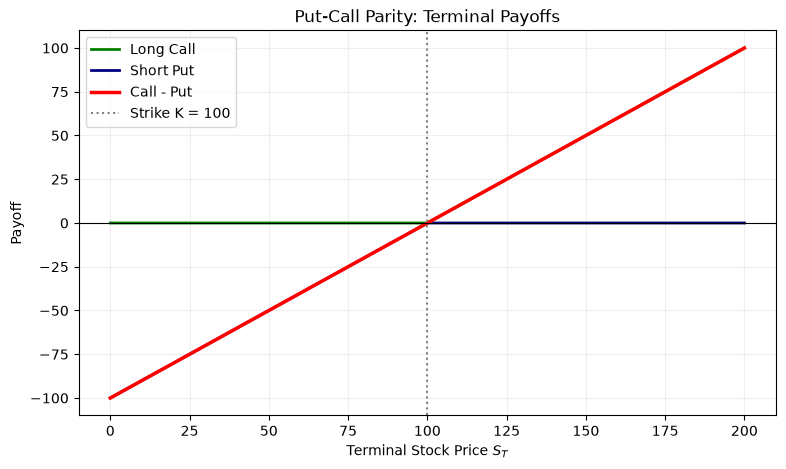

In [13]:
import numpy as np
import matplotlib.pyplot as plt

K = 100
S_T = np.linspace(0, 200, 500)

# Terminal payoffs
call = np.maximum(S_T - K, 0)
short_put = -np.maximum(K - S_T, 0)
call_minus_put = call + short_put

plt.figure(figsize=(9, 5))

plt.plot(S_T, call, label='Long Call', color='green',linewidth=2)
plt.plot(S_T, short_put, label='Short Put', color='navy', linewidth=2)
plt.plot(S_T, call_minus_put, label='Call - Put', color='red', linewidth=2.5)

plt.axvline(K, color='gray', linestyle=':', label=f'Strike K = {K}')
plt.axhline(0, color='black', linewidth=0.8)

plt.xlabel('Terminal Stock Price $S_T$')
plt.ylabel('Payoff')
plt.title('Put-Call Parity: Terminal Payoffs')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## Delta Hedging

To hedge an option, we need to understand how its value changes when the underlying stock price moves.

### The Greeks

Let $V(s,t,r,\sigma)$ denote an option's **arbitrage-free price**, with strike $K$ and maturity $T$ fixed.

Use $V=C$ for a call and $V=P$ for a put.

The **Greeks** measure the sensitivity of an option's price to changes in market variables:

| Greek | Definition | Interpretation |
|---|---|---|
| **Delta** $\Delta$ | $V_s$ | Sensitivity to stock price |
| **Gamma** $\Gamma$ | $V_{ss}$ | Sensitivity of Delta to stock price |
| **Theta** $\Theta$ | $V_t=-V_\tau$ | Sensitivity to time |
| **Rho** $\rho$ | $V_r$ | Sensitivity to interest rate |
| **Vega** | $V_\sigma$ | Sensitivity to volatility |

**Why Delta Hedging works (locally):**

For a small stock-price change $\delta s$, with other variables fixed:

- **Short one option:** its value changes by approximately $-\Delta\,\delta s$.
- **Long $q$ shares:** the stock position changes by $q\,\delta s$.

The combined first-order change is:

$$
\delta\Pi\approx(q-\Delta)\delta s
$$

Choosing

$$
\boxed{q=\Delta}
$$

cancels the **first-order stock-price risk**.

> **Note:** Delta hedging does not eliminate higher-order risks such as Gamma. It must be adjusted as the stock price and time change.



### Delta-Hedging Strategy

Under the Black–Scholes model:

$$
\boxed{\Delta_{\text{call}}=C_s(s,t)=N(d_1)}
$$

$$
\boxed{\Delta_{\text{put}}=P_s(s,t)=N(d_1)-1}
$$

**Replication Strategy:**

- Start with initial wealth equal to the option price $C(S_0,0)$.
- At each time $t<T$, hold $\Delta_{\text{call}}(S_t,t)$ shares.
- Keep the remaining wealth in the risk-free bank account (a negative balance represents borrowing).
- Rebalance continuously while maintaining a **self-financing portfolio**.

The portfolio value satisfies:

$$
\boxed{\Pi_t=C(S_t,t)}
$$

At maturity:

$$
\boxed{\Pi_T=(S_T-K)^+}
$$

Hence, the strategy **replicates the European call payoff** under the Black–Scholes assumptions.

### Gamma

Gamma measures how quickly Delta changes as the underlying stock price changes:

$$
\Gamma=\frac{\partial\Delta}{\partial s}
=\frac{\partial^2 V}{\partial s^2}
$$

For a European call or put:

$$
\boxed{
\Gamma_{\text{call}}=\Gamma_{\text{put}}
=\frac{\varphi(d_1)}{s\sigma\sqrt{\tau}}
}
$$

where $\varphi(d_1)$ is the standard normal PDF.

> **Key insight:** Delta determines the stock position needed for hedging, while Gamma measures how quickly that hedge position needs to change.



## **Black–Scholes PDE and Replication Proof**

**Goal:** Construct a self-financing portfolio whose value $\Pi_t$ matches a candidate option price $V(S_t,t)$.

Define the **replication error**:

$$
E_t=\Pi_t-V(S_t,t),\qquad E_0=0
$$

We want to show that $E_t=0$ throughout the trading period.

### Step 1 — Self-financing Wealth Process

Holding $q_t$ shares, with the remaining wealth in the bank account:

$$
d\Pi_t=q_t\,dS_t+r(\Pi_t-q_tS_t)\,dt
$$

Substituting the GBM equation:

$$
\boxed{
d\Pi_t=[r\Pi_t+q_tS_t(\mu-r)]dt
+q_t\sigma S_t\,dW_t
}
$$

### Step 2 — Apply Itô's Lemma

For the candidate option price $V(S_t,t)$:

$$
\boxed{
dV=
\left(V_t+\mu S_tV_s+\frac12\sigma^2S_t^2V_{ss}\right)dt
+\sigma S_tV_s\,dW_t
}
$$

Here $V_t$, $V_s$ and $V_{ss}$ denote partial derivatives.

### Step 3 — Choose Delta Hedging

To match the responses of the portfolio and the option to the same Wiener increment, compare their $dW_t$ coefficients:

$$
q_t\sigma S_t=V_s\sigma S_t
$$

Therefore,

$$
\boxed{q_t=V_s(S_t,t)=\Delta_t}
$$

This choice cancels the stochastic term in $dE_t=d\Pi_t-dV$.

### Step 4 — Derive the Error Process

Substituting $q_t=V_s$:

$$
\begin{aligned}
dE_t
&=d\Pi_t-dV\\
&=\left[r\Pi_t-rS_tV_s-V_t
-\frac12\sigma^2S_t^2V_{ss}\right]dt
\end{aligned}
$$

Since $\Pi_t=E_t+V$:

$$
\boxed{
dE_t=
\left[
rE_t-
\left(
V_t+\frac12\sigma^2S_t^2V_{ss}
+rS_tV_s-rV
\right)
\right]dt
}
$$

**Key observation:** Both the random term $dW_t$ and the stock's expected return $\mu$ have disappeared.

### Step 5 — Black–Scholes PDE

To keep the replication error equal to zero, require:

$$
\boxed{
V_t+\frac12\sigma^2s^2V_{ss}+rsV_s-rV=0
}
$$

This is the **Black–Scholes Partial Differential Equation (PDE)**.

If $V$ satisfies the PDE, the error process becomes:

$$
dE_t=rE_t\,dt
$$

Since $E_0=0$:

$$
\boxed{E_t=E_0e^{rt}=0}
$$

Thus,

$$
\boxed{\Pi_t=V(S_t,t)}
$$

For a European call, the terminal condition is:

$$
V(s,T)=(s-K)^+
$$

Therefore, the portfolio replicates the call payoff:

$$
\boxed{\Pi_T=(S_T-K)^+}
$$

> **Key insight:** Delta hedging matches the portfolio's exposure to the option's stock-price risk. The Black–Scholes PDE ensures that their remaining drift terms also agree. Together, they guarantee exact replication under the model's assumptions.



## **Comparison of Option Pricing Methods**

We have studied three approaches to option pricing:

| | Binomial Model | Monte Carlo | Black–Scholes |
|---|---|---|---|
| **Approach** | Discrete-time pricing model | Numerical simulation method | Continuous-time pricing model |
| **Stock process** | Up/down price movements | Simulated stock-price paths | Geometric Brownian Motion |
| **Pricing method** | Backward induction / replication | Discounted risk-neutral expected payoff | Analytical formula / replication |
| **Main advantage** | Intuitive and flexible | Useful for complex, path-dependent payoffs | Fast and exact within its assumptions |
| **Main limitation** | Computational cost increases with steps | Sampling error; early exercise is harder | Restrictive market assumptions |

### Key Pricing Relationships

**1. Binomial Model — Risk-Neutral Pricing**

For a one-period binomial model:

$$
V_0=e^{-rT}\left[p^*V_u+(1-p^*)V_d\right]
$$

where $p^*$ is the risk-neutral up probability.

**2. Monte Carlo — Numerical Pricing**

Simulate $M$ terminal stock prices under a risk-neutral model:

$$
\boxed{
\hat V_0=e^{-rT}\frac{1}{M}
\sum_{j=1}^{M}g(S_T^{(j)})
}
$$

The estimate approaches the risk-neutral price as $M$ increases.

**3. Black–Scholes — Analytical Pricing**

For a European call:

$$
\boxed{C(s,t)=sN(d_1)-Ke^{-r\tau}N(d_2)}
$$

The price equals the initial cost of a self-financing replicating portfolio.

### How Are They Connected?

Under the appropriate assumptions, all three approaches can produce the **same arbitrage-free price**.

- **Binomial:** Discrete replication and risk-neutral valuation.
- **Monte Carlo:** Numerically estimates a risk-neutral expectation.
- **Black–Scholes:** Continuous replication and an analytical pricing formula.

> **Key insight:** Monte Carlo is a computational method rather than a separate no-arbitrage pricing theory. The Black–Scholes formula and Monte Carlo can price the same European option under the same GBM assumptions.
